# **Imports**

Bellow are all the **Modules** used in this **Notebook**.

In [1]:
# Common
import os
import keras
import numpy as np
from glob import glob 
from tqdm import tqdm 
import tensorflow as tf

# Data
import pandas as pd
from keras.preprocessing.image import ImageDataGenerator

# Data Viz
import seaborn as sns
import matplotlib.pyplot as plt

# Model 
from keras import Sequential
from keras.layers import GlobalAvgPool2D, Dense, Dropout
from keras.models import load_model

# Pre-Trained Models
from tensorflow.keras.applications import ResNet50, ResNet50V2, InceptionV3, Xception

# Callbacks 
from keras.callbacks import EarlyStopping, ModelCheckpoint

# **Data**

Our first task is to load the data set and understand it.

In [2]:
class_names = sorted(os.listdir('../input/coffee-bean-dataset-resized-224-x-224/train'))
n_classes = len(class_names)
class_names

['Dark', 'Green', 'Light', 'Medium']

There are **4 Classes** in the **Dataset**, let's see how each class is **Distribited** across the **Dataset**.

In [3]:
class_dis = [len(glob("../input/coffee-bean-dataset-resized-224-x-224/train/" + name + "/*.png")) for name in class_names]
class_dis

[300, 300, 300, 300]

Great, all the classes are **equally distributed**. This is a sign that **model cannot be biased**.

In [4]:
data = pd.read_csv('../input/coffee-bean-dataset-resized-224-x-224/Coffee Bean.csv')
data.head()

,class index,filepaths,labels,data set
0,0,train/Dark/dark (1).png,Dark,train
1,0,train/Dark/dark (10).png,Dark,train
2,0,train/Dark/dark (100).png,Dark,train
3,0,train/Dark/dark (101).png,Dark,train
4,0,train/Dark/dark (102).png,Dark,train


It's time to load the images.

In [5]:
# Initialize Generator
train_gen = ImageDataGenerator(
    rescale=1./255, 
    horizontal_flip=True, 
    rotation_range=20, 
    validation_split=0.2)

test_gen = ImageDataGenerator(rescale=1./255)

# Load Data
path = "../input/coffee-bean-dataset-resized-224-x-224/"
train_ds = train_gen.flow_from_directory(path + "train", target_size=(256,256), shuffle=True, batch_size=32, subset="training", class_mode='binary')
valid_ds = train_gen.flow_from_directory(path + "train", target_size=(256,256), shuffle=True, batch_size=32, subset="validation", class_mode='binary')
test_ds = train_gen.flow_from_directory(path + "test", target_size=(256,256), shuffle=True, batch_size=32, class_mode='binary')

Found 960 images belonging to 4 classes.
Found 240 images belonging to 4 classes.
Found 400 images belonging to 4 classes.


# **Data Viz**

In [6]:
def show_image(img, title=None):
    plt.imshow(img)
    plt.title(title)
    plt.axis('off')

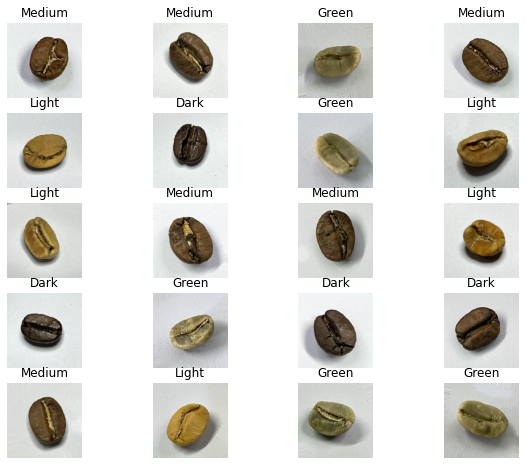

In [7]:
plt.figure(figsize=(10,8))
i=1
for images, labels in iter(train_ds):
    
    id = np.random.randint(len(images))
    image = images[id]
    label = labels[id]

    plt.subplot(5,4,i)
    show_image(image, title=class_names[int(label)])

    i+=1
    if i>=21: break

plt.show()

It can be a **little tough** for the model to distinguish between **"Dark" and "Medium"**, **"Light" and "Green"** are easily distinguishable.

---
As the **total number** of **images** is low than what it usually take to **train a Neural Network from Scratch**, we will use the **Transfer Learning Technique**.

# **ResNet50V2**

In [8]:
# # Initialize Base Model
# name = "ResNet50V2"
# base_model = ResNet50V2(include_top=False, weights='imagenet', input_shape=(256,256,3))
# base_model.trainable = False

# # Model
# resnet_50V2 = Sequential([
#     base_model, 
#     GlobalAvgPool2D(),
#     Dense(256, activation='relu'),
#     Dropout(0.2),
#     Dense(n_classes, activation='softmax')
# ])


# # Compile
# resnet_50V2.compile(
#     loss='sparse_categorical_crossentropy',
#     optimizer='adam',
#     metrics=['accuracy']
# )

# # Callbacks
# cbs = [EarlyStopping(patience=3, restore_best_weights=True), ModelCheckpoint(name + ".h5", save_best_only=True)]

# # Training
# resnet_50V2.fit(train_ds, validation_data=valid_ds, epochs=50, callbacks=cbs)

In [9]:
model_path = '../input/coffee-bean-classifier-resnet50v2/ResNet50V2-Coffee-Beans.h5'
model = load_model(model_path)

2022-09-24 02:47:42.497375: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


In [10]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
resnet50v2 (Functional)      (None, 8, 8, 2048)        23564800  
_________________________________________________________________
global_average_pooling2d_1 ( (None, 2048)              0         
_________________________________________________________________
dense_2 (Dense)              (None, 256)               524544    
_________________________________________________________________
dropout_1 (Dropout)          (None, 256)               0         
_________________________________________________________________
dense_3 (Dense)              (None, 4)                 1028      
Total params: 24,090,372
Trainable params: 525,572
Non-trainable params: 23,564,800
_________________________________________________________________


In [11]:
model.evaluate(test_ds)

2022-09-24 02:47:47.207035: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


13/13 [==============================] - 38s 3s/step - loss: 0.0604 - accuracy: 0.9800


[0.06035727635025978, 0.9800000190734863]

I tried out **ResNet50, ResNet50V2, Inception and Xception**. Of which **ResNet50V2** is the **fastest** and have the **highest accuracy**. Both **Xception** and **ResNet50V2** have the **same training accuracy** of **98%** and **validation accuracy** of **95%**, but **ResNet50V2** converged to the **Optimal Faster**.

$Scores : $

* $ResNet50$ 
 * **Epochs :** 30,  **Loss :** 0.56-0.54, **T Acc :** 0.73, **V Acc :** 0.80.

* $ResNet50V2$ 
 * **Epochs :** 7,  **Loss :** 0.04-0.09, **T Acc :** 0.98, **V Acc :** 0.95.

* $InceptionV3$ 
 * **Epochs :** 9,  **Loss :** 0.07-0.15, **T Acc :** 0.97, **V Acc :** 0.94.

* $Xception$ 
 * **Epochs :** 11,  **Loss :** 0.05-0.13, **T Acc :** 0.98, **V Acc :** 0.95.

---
Here, 
* **Loss** represents the Training Loss and the Validation Loss.
* **T Acc** represents the Training Accuracy
* **V Acc** represents the Validation Accuracy

--- 
As you can easily notice that **ResNet50V2** is **leading**. It converged to the **optimal solution faster** than any other network, maintained the **robustness** both in **Loss and Accuracy**. It shows **no sign** of **overfitting** or **underfitting**, but shows a **clear sign** for **A Robust Network.** 

# **Evaluation**

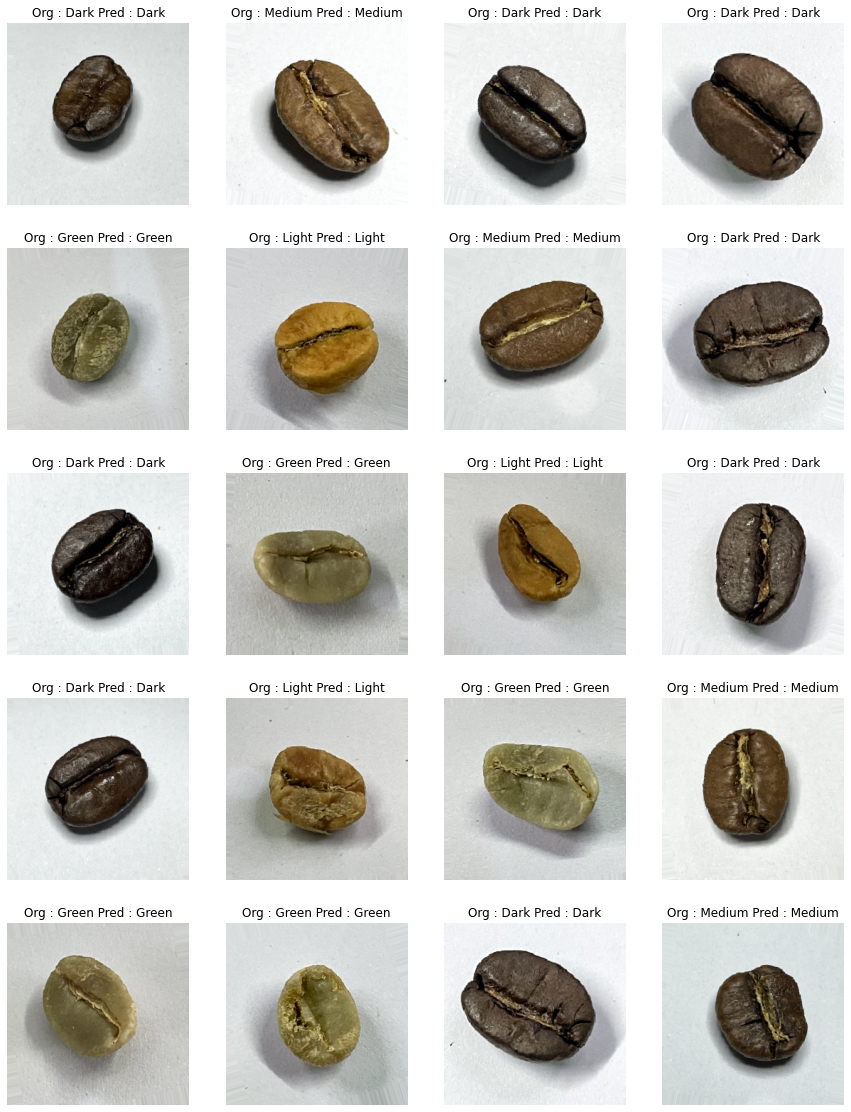

In [12]:
plt.figure(figsize=(15,20))
i=1
for images, labels in iter(test_ds):
    
    # Load Random Image, label
    id = np.random.randint(len(images))
    image = images[id]
    label = labels[id]

    # Make Prediction
    pred_label = class_names[int(np.argmax(model.predict(image[np.newaxis,...])))]

    # Plot Prediction
    plt.subplot(5,4,i)
    show_image(image, title=f"Org : {class_names[int(label)]} Pred : {pred_label}")

    # Increment and Break
    i+=1
    if i>=21: break

# Show
plt.show()

I thought the model will get confused between **medium and dark seeds**. But to my surprise, the model is **super awesome**. It's predictions are **perfect** and I was **not able to find any error**.

**Thank You!!**

---
**DeepNets**